# Named entity recognition (NER) with Keras

The sentiment notebook gave **one label per sentence**. NER gives **one label per word**: the RNN outputs a tag at every time step, marking which words are people, organisations or locations.

```
Alice   works  at  Google  in  London
B-PER   O      O   B-ORG   O   B-LOC
```

- Tags use the BIO scheme: `B-` begins an entity, `I-` continues it, `O` is outside any entity
- Dataset: 50 short annotated sentences with `PER`, `ORG` and `LOC` entities
- Model: embedding, bidirectional RNN that returns every step, softmax per word

Install if needed: `pip install tensorflow matplotlib`

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Dataset (50 annotated sentences)

Entities are written as `[TYPE words]` and converted into one BIO tag per word.

In [2]:
annotated = [
    "[PER Alice] works at [ORG Google] in [LOC London]",
    "[PER Bob] lives in [LOC Paris]",
    "[PER Priya] joined [ORG Infosys] last year",
    "[ORG Microsoft] opened a new office in [LOC Bengaluru]",
    "[PER John Smith] visited [LOC Japan] in spring",
    "[PER Maria] flew from [LOC London] to [LOC New York]",
    "[ORG Amazon] hired [PER David] in [LOC India]",
    "[PER Alice] met [PER Bob] in [LOC Paris]",
    "[ORG Tesla] built a factory in [LOC Japan]",
    "[PER Priya] moved to [LOC Bengaluru] for work",
    "[ORG Apple] launched a phone in [LOC New York]",
    "[PER David] works at [ORG Microsoft]",
    "[PER Maria] joined [ORG Tesla] in [LOC London]",
    "[ORG Google] hired [PER John Smith] last year",
    "[PER Bob] visited [LOC India] with [PER Priya]",
    "[ORG Infosys] has an office in [LOC New York]",
    "[PER Alice] moved from [LOC Paris] to [LOC Bengaluru]",
    "[ORG Amazon] opened a store in [LOC London]",
    "[PER John Smith] works at [ORG Apple] in [LOC Japan]",
    "[PER Priya] met [PER Maria] at [ORG Google]",
    "[PER David] lives in [LOC New York]",
    "[ORG Tesla] hired [PER Alice] last year",
    "[PER Maria] visited [LOC Japan] in summer",
    "[ORG Microsoft] launched a product in [LOC India]",
    "[PER Bob] works at [ORG Amazon] in [LOC Paris]",
    "[PER Priya] flew to [LOC London] for [ORG Infosys]",
    "[ORG Apple] opened an office in [LOC Bengaluru]",
    "[PER David] met [PER John Smith] in [LOC London]",
    "[PER Alice] joined [ORG Apple] in spring",
    "[ORG Google] has a campus in [LOC India]",
    "[PER Bob] moved to [LOC Japan] last year",
    "[PER Maria] works at [ORG Infosys] in [LOC Bengaluru]",
    "[ORG Amazon] hired [PER Priya] in summer",
    "[PER John Smith] flew from [LOC Paris] to [LOC Japan]",
    "[ORG Tesla] opened a store in [LOC Paris]",
    "[PER David] joined [ORG Google] in [LOC New York]",
    "[PER Alice] visited [LOC India] for work",
    "[ORG Microsoft] hired [PER Bob] last year",
    "[PER Priya] lives in [LOC London]",
    "[ORG Apple] hired [PER Maria] in [LOC New York]",
    "[PER Bob] met [PER Alice] at [ORG Tesla]",
    "[ORG Infosys] opened a campus in [LOC Japan]",
    "[PER John Smith] moved to [LOC Bengaluru] in summer",
    "[PER David] flew to [LOC Paris] for [ORG Amazon]",
    "[PER Maria] lives in [LOC India]",
    "[ORG Google] launched a product in [LOC Japan]",
    "[PER Priya] works at [ORG Tesla] in [LOC Bengaluru]",
    "[PER Alice] met [PER David] in [LOC New York]",
    "[PER Bob] joined [ORG Infosys] in [LOC London]",
    "[ORG Microsoft] has an office in [LOC Paris]",
]

def parse(s):
    tokens, tags, pos = [], [], 0
    for m in re.finditer(r"\[(PER|ORG|LOC) ([^\]]+)\]", s):
        for w in s[pos:m.start()].split():
            tokens.append(w); tags.append("O")
        for j, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(("B-" if j == 0 else "I-") + m.group(1))
        pos = m.end()
    for w in s[pos:].split():
        tokens.append(w); tags.append("O")
    return tokens, tags

data = [parse(s) for s in annotated]
tag_names = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC"]
tag2id = {t: i for i, t in enumerate(tag_names)}
print(len(data), "sentences")
for tokens, tags in data[:3]:
    print(" ".join(f"{w}/{t}" for w, t in zip(tokens, tags)))

50 sentences
Alice/B-PER works/O at/O Google/B-ORG in/O London/B-LOC
Bob/B-PER lives/O in/O Paris/B-LOC
Priya/B-PER joined/O Infosys/B-ORG last/O year/O


## 2. Split, vectorize and pad

In [3]:
idx = np.random.permutation(len(data))
test_idx, train_idx = idx[:10], idx[10:]
train_data = [data[i] for i in train_idx]
test_data  = [data[i] for i in test_idx]

MAXLEN = max(len(t) for t, _ in data)

# Case-sensitive, whitespace-split vocabulary fitted on the training split only.
# Id 0 is padding, id 1 is [UNK].
vectorizer = layers.TextVectorization(standardize=None, split="whitespace",
                                      output_mode="int", output_sequence_length=MAXLEN)
vectorizer.adapt(tf.constant([" ".join(t) for t, _ in train_data]))
VOCAB = len(vectorizer.get_vocabulary())

def make_xy(dataset):
    X = vectorizer(tf.constant([" ".join(t) for t, _ in dataset])).numpy()
    y = keras.utils.pad_sequences([[tag2id[t] for t in tags] for _, tags in dataset],
                                  maxlen=MAXLEN, padding="post", value=0)
    return X, y

X_train, y_train = make_xy(train_data)
X_test,  y_test  = make_xy(test_data)
print("vocab size:", VOCAB, "| max length:", MAXLEN, "| X_train:", X_train.shape, "| y_train:", y_train.shape)

vocab size: 54 | max length: 7 | X_train: (40, 7) | y_train: (40, 7)


## 3. The model

Compared with sentiment analysis, two things change:

- `return_sequences=True` makes the RNN output a hidden state at **every** word instead of only the last one
- `Bidirectional` reads the sentence left-to-right and right-to-left, so each word sees the words before and after it ("works **at** Google" helps tag Google as an organisation)

The softmax layer is applied to every word, and `mask_zero=True` keeps the padding out of the loss.

In [4]:
model = keras.Sequential([
    keras.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB, 32, mask_zero=True),
    layers.Bidirectional(layers.SimpleRNN(32, return_sequences=True)),
    layers.Dense(len(tag_names), activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01, clipnorm=5.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 7, 32)          │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 7, 64)          │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7, 7)           │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,343 (24.78 KB)

 Trainable params: 6,343 (24.78 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Training

In [5]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=60,
    batch_size=8,
    verbose=0,
)

h = history.history
for e in [0, 9, 19, 29, 39, 49, 59]:
    print(f"epoch {e + 1:3d} | train loss {h['loss'][e]:.3f} acc {h['accuracy'][e]:.2f}"
          f" | test loss {h['val_loss'][e]:.3f} acc {h['val_accuracy'][e]:.2f}")

epoch   1 | train loss 1.585 acc 0.48 | test loss 1.002 acc 0.54
epoch  10 | train loss 0.001 acc 1.00 | test loss 0.002 acc 1.00
epoch  20 | train loss 0.000 acc 1.00 | test loss 0.001 acc 1.00
epoch  30 | train loss 0.000 acc 1.00 | test loss 0.001 acc 1.00
epoch  40 | train loss 0.000 acc 1.00 | test loss 0.001 acc 1.00
epoch  50 | train loss 0.000 acc 1.00 | test loss 0.001 acc 1.00
epoch  60 | train loss 0.000 acc 1.00 | test loss 0.000 acc 1.00


## 5. Learning curves

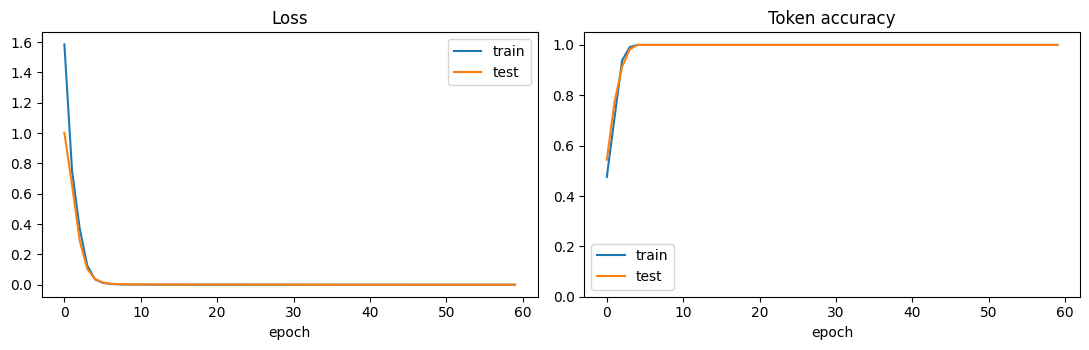

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="test")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="test")
ax[1].set_title("Token accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.05); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Entity-level scoring

Token accuracy is misleading because most words are `O`. The standard NER metric counts an entity as correct only if its type **and** its full span match exactly.

In [7]:
def get_entities(seq):
    ents, start, typ = set(), None, None
    for i, t in enumerate(list(seq) + ["O"]):
        if t == "O" or t.startswith("B-") or (t.startswith("I-") and t[2:] != typ):
            if typ is not None:
                ents.add((typ, start, i))
            start, typ = (i, t[2:]) if t != "O" else (None, None)
    return ents

def predict_tags(X, lengths):
    probs = model.predict(X, verbose=0)
    ids = probs.argmax(axis=-1)
    return [[tag_names[i] for i in row[:n]] for row, n in zip(ids, lengths)]

def entity_scores(true_tags, pred_tags):
    tp = fp = fn = 0
    for t, p in zip(true_tags, pred_tags):
        te, pe = get_entities(t), get_entities(p)
        tp += len(te & pe); fp += len(pe - te); fn += len(te - pe)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

test_true = [tags for _, tags in test_data]
test_pred = predict_tags(X_test, [len(t) for t, _ in test_data])
p, r, f1 = entity_scores(test_true, test_pred)
print(f"entity precision {p:.2f} | recall {r:.2f} | F1 {f1:.2f}")

entity precision 1.00 | recall 1.00 | F1 1.00


## 7. Test set predictions

In [8]:
for (tokens, true), pred in zip(test_data, test_pred):
    ok = "OK " if get_entities(true) == get_entities(pred) else "BAD"
    print(ok, "|", " ".join(f"{w}/{t}" for w, t in zip(tokens, pred)))
    if ok == "BAD":
        print("     true:", " ".join(f"{w}/{t}" for w, t in zip(tokens, true)))

OK  | Google/B-ORG hired/O John/B-PER Smith/I-PER last/O year/O
OK  | Apple/B-ORG hired/O Maria/B-PER in/O New/B-LOC York/I-LOC
OK  | Bob/B-PER moved/O to/O Japan/B-LOC last/O year/O
OK  | Google/B-ORG launched/O a/O product/O in/O Japan/B-LOC
OK  | Amazon/B-ORG opened/O a/O store/O in/O London/B-LOC
OK  | Bob/B-PER joined/O Infosys/B-ORG in/O London/B-LOC
OK  | Apple/B-ORG opened/O an/O office/O in/O Bengaluru/B-LOC
OK  | Priya/B-PER flew/O to/O London/B-LOC for/O Infosys/B-ORG
OK  | Amazon/B-ORG hired/O Priya/B-PER in/O summer/O
OK  | Priya/B-PER met/O Maria/B-PER at/O Google/B-ORG


## 8. Try your own sentence

Use names from the dataset for best results. Words the model has never seen become `[UNK]`, and a plain embedding cannot tell that "Delhi" looks like a place.

In [9]:
def tag_sentence(sentence):
    tokens = sentence.split()
    X = vectorizer(tf.constant([sentence])).numpy()
    tags = predict_tags(X, [min(len(tokens), MAXLEN)])[0]
    ents = [(typ, " ".join(tokens[s:e])) for typ, s, e in sorted(get_entities(tags), key=lambda x: x[1])]
    print(" ".join(f"{w}/{t}" for w, t in zip(tokens, tags)))
    print("entities:", ents, "\n")

for s in ["Priya works at Google in Paris", "Bob visited Japan with Alice", "Amazon opened an office in Bengaluru"]:
    tag_sentence(s)

Priya/B-PER works/O at/O Google/B-ORG in/O Paris/B-LOC
entities: [('PER', 'Priya'), ('ORG', 'Google'), ('LOC', 'Paris')] 

Bob/B-PER visited/O Japan/B-LOC with/O Alice/B-PER
entities: [('PER', 'Bob'), ('LOC', 'Japan'), ('PER', 'Alice')] 

Amazon/B-ORG opened/O an/O office/O in/O Bengaluru/B-LOC
entities: [('ORG', 'Amazon'), ('LOC', 'Bengaluru')] 



## Notes

- 50 sentences is a toy dataset, and the 10-sentence test set is noisy. It also reuses the same names, so the model partly memorises them.
- Real NER needs unseen names. Add features that generalise: character-level embeddings, a capitalisation flag, or pretrained word vectors.
- Swap `SimpleRNN` for `LSTM` or `GRU` to handle longer sentences. For stronger results, add a CRF layer or fine-tune a transformer such as BERT.